# Data import

In [3]:
# Dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score
from data_engineering import make_splits, load_raw, clean, build_features

In [4]:
# Load data
raw_data = load_raw()
df = clean(raw_data)
out = make_splits(df)

In [5]:
data = []
for ts, (X_tr, X_te, y_tr, y_te, info) in out.items():
        data.append((ts, X_tr, X_te, y_tr, y_te, info))
        print(f"test={ts:.0%} -> train {X_tr.shape}, test {X_te.shape}, "
              f"%>50K train={y_tr.mean():.3f} test={y_te.mean():.3f}")

test=10% -> train (43911, 88), test (4879, 88), %>50K train=0.239 test=0.239
test=20% -> train (39032, 88), test (9758, 88), %>50K train=0.239 test=0.239
test=30% -> train (34153, 88), test (14637, 88), %>50K train=0.239 test=0.239
test=40% -> train (29274, 88), test (19516, 88), %>50K train=0.239 test=0.239


s, X_tr, X_te, y_tr, y_te, info
0, 1,    2,    3,    4,    5

# Perceptron

In [6]:
# Activation function Step
def g(z):
    if z >= 0:
        return 1
    else:
        return 0

In [7]:
def run(inputs, ws, bias):
    # We can see that the forward run of the perceptron is just a dot product. Numpy does it pretty well
    z = np.dot(inputs, ws) + bias
    return g(z)


In [8]:
def update(inputs, ws, bias, e, alpha=0.05):
    ws = ws + alpha * e * inputs
    bias = bias + alpha * e
    return ws, bias

In [9]:
def train(df, alpha,epochs):
    inputs = df[1].to_numpy()[:, :4] # Use only the first 4 features
    targets = df[3].to_numpy()
    ws = np.random.rand(inputs.shape[1])
    bias = 0.0
    history = []
    for epoch in range(epochs):
        mistakes = 0
        for i in range(len(inputs)):
            y_hat = run(inputs[i], ws, bias)
            e = targets[i] - y_hat
            if e != 0:
                mistakes += 1
                ws, bias = update(inputs[i], ws, bias, e, alpha)
        history.append(mistakes)
        #print(f"Epoch {epoch+1}/{epochs} -> Mistakes: {mistakes}")
    return ws, bias, history

In [10]:
ws, bias, history = train(data[0], 0.001, 200)

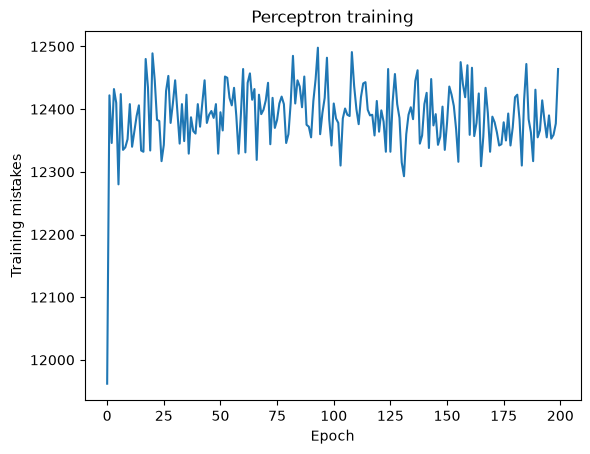

In [11]:
plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Training mistakes")
plt.title("Perceptron training")
plt.show()

# Test the model

In [12]:
def test(df, ws, bias):
    inputs = df[2].to_numpy()[:, :4] # Use only the first 4 features
    targets = df[4].to_numpy()
    mistakes = 0
    for i in range(len(inputs)):
        y_hat = run(inputs[i], ws, bias)
        e = targets[i] - y_hat
        if e != 0:
            mistakes += 1
    return mistakes

In [13]:
erors = test(data[0], ws, bias)
error_rate = erors / len(data[0][2])
print(f"Test error rate: {error_rate:.3f}")

Test error rate: 0.308


# Compare with diferent data sizes

In [16]:
import json
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

METRICS_FILE = Path("model_metrics.json")

def save_metrics(model, test_size, y_true, y_pred):
    results = (
        json.loads(METRICS_FILE.read_text())
        if METRICS_FILE.exists()
        else {}
    )
    results.setdefault(model, {})[f"{test_size:.0%}"] = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1_score": float(f1_score(y_true, y_pred, zero_division=0)),
        "samples": int(len(y_true)),
    }
    METRICS_FILE.write_text(json.dumps(results, indent=2))

In [17]:
def run_perceptron(i, alpha, epochs):
    print(f"Running perceptron for test={i+1} with alpha={alpha} and epochs={epochs}")
    ws, bias, history = train(data[i], alpha, epochs)
    plt.plot(history)
    plt.xlabel("Epoch")
    plt.ylabel("Training mistakes")
    plt.title(f"Perceptron training (test={i:.0%})")
    plt.show()
    errors = test(data[i], ws, bias)
    print(f"Test error rate: {errors / len(data[i][2]):.3f}")
    predictions = np.array([run(x, ws, bias) for x in data[i][2].to_numpy()[:, :4]])
    print(classification_report(data[i][4], predictions))
    save_metrics("perceptron", data[i][0], data[i][4].to_numpy(), predictions)

Running perceptron for test=1 with alpha=0.001 and epochs=200


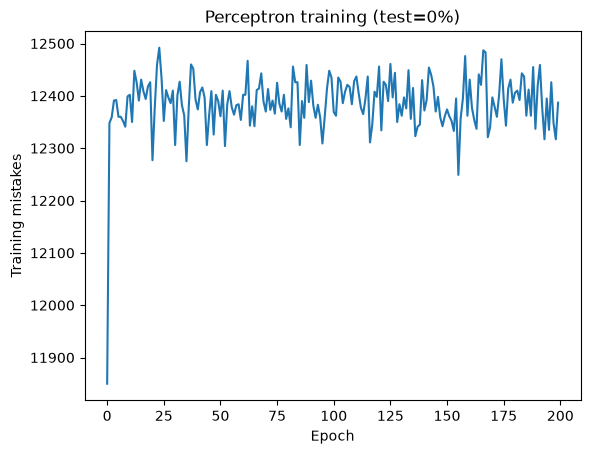

Test error rate: 0.334
              precision    recall  f1-score   support

           0       0.79      0.77      0.78      3711
           1       0.32      0.34      0.33      1168

    accuracy                           0.67      4879
   macro avg       0.55      0.55      0.55      4879
weighted avg       0.67      0.67      0.67      4879

Running perceptron for test=2 with alpha=0.001 and epochs=200


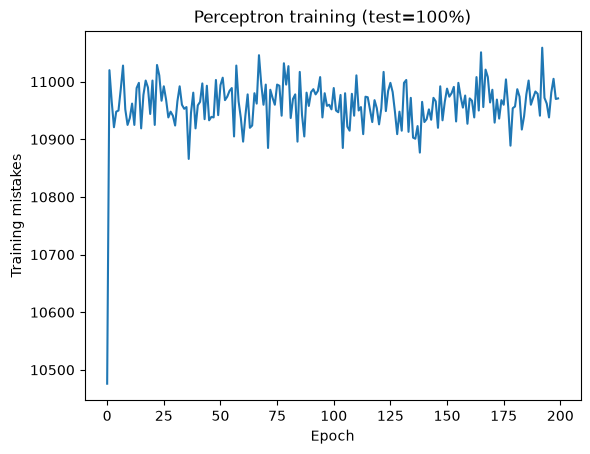

Test error rate: 0.215
              precision    recall  f1-score   support

           0       0.79      0.98      0.87      7422
           1       0.71      0.17      0.28      2336

    accuracy                           0.78      9758
   macro avg       0.75      0.57      0.57      9758
weighted avg       0.77      0.78      0.73      9758

Running perceptron for test=3 with alpha=0.001 and epochs=200


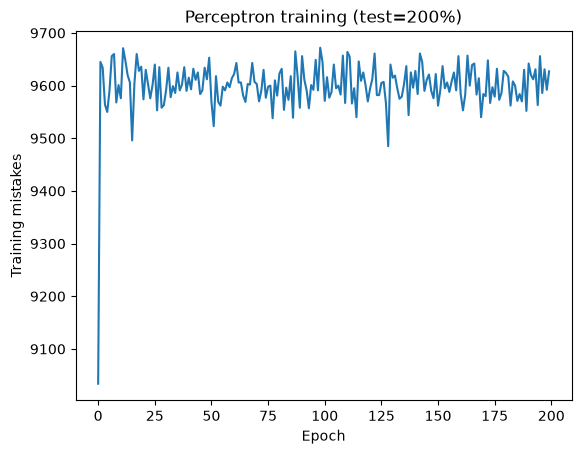

Test error rate: 0.323
              precision    recall  f1-score   support

           0       0.80      0.77      0.78     11133
           1       0.34      0.38      0.36      3504

    accuracy                           0.68     14637
   macro avg       0.57      0.58      0.57     14637
weighted avg       0.69      0.68      0.68     14637

Running perceptron for test=4 with alpha=0.001 and epochs=200


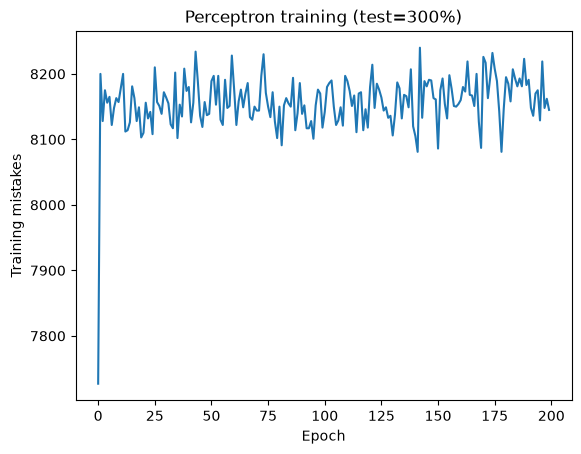

Test error rate: 0.254
              precision    recall  f1-score   support

           0       0.86      0.79      0.83     14844
           1       0.48      0.60      0.53      4672

    accuracy                           0.75     19516
   macro avg       0.67      0.69      0.68     19516
weighted avg       0.77      0.75      0.75     19516



In [18]:
for i in range(len(data)):
    run_perceptron(i, 0.001, 200) 